In [1]:
import os, sys, time, json, shutil, subprocess, warnings
warnings.filterwarnings("ignore")

try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
if shutil.which("java") is None:
    subprocess.run("apt-get -qq install -y openjdk-17-jdk-headless > /dev/null", shell=True, check=True)


from google.colab import drive
drive.mount("/content/drive")
PERSIST_DIR = "/content/drive/MyDrive/7006SCN_GSOD"
SCRATCH_DIR = "/content/gsod_scratch"
LOCAL_DIR   = "/content/gsod_local"

def sp(path):
    return path

RAW_DIR     = SCRATCH_DIR + "/raw_csv"
ARCHIVE_DIR = PERSIST_DIR + "/archives"
PARQUET_RAW = LOCAL_DIR + "/parquet/gsod_raw"
FEATURES    = LOCAL_DIR + "/parquet/gsod_features"
PRED_DIR    = LOCAL_DIR + "/parquet/predictions"
MODELS_DIR  = LOCAL_DIR + "/models"
OUT_DIR     = PERSIST_DIR + "/outputs"
for d in [PERSIST_DIR, SCRATCH_DIR, LOCAL_DIR, ARCHIVE_DIR, MODELS_DIR, OUT_DIR]:
    os.makedirs(d, exist_ok=True)

def backup_to_drive(local_path):
    dest = local_path.replace(LOCAL_DIR, PERSIST_DIR)
    shutil.rmtree(dest, ignore_errors=True)
    shutil.copytree(local_path, dest)
    print("backed up ->", dest)

def restore_from_drive(local_path):
    if not os.path.exists(local_path):
        shutil.copytree(local_path.replace(LOCAL_DIR, PERSIST_DIR), local_path)
        print("restored <-", local_path)

YEARS       = [2020, 2021, 2022, 2023]
TRAIN_YEARS = [2020, 2021, 2022]
TEST_YEAR   = 2023
SEED        = 42

from pyspark.sql import SparkSession, functions as F, Window
from pyspark import StorageLevel
TOTAL_RAM_GB = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
DRIVER_MEM = f"{max(2, int(TOTAL_RAM_GB * 0.7))}g"

spark = (SparkSession.builder
         .master("local[*]")
         .appName("7006SCN_GSOD_Task1")
         .config("spark.driver.memory", DRIVER_MEM)
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
         .config("spark.sql.files.maxPartitionBytes", str(128 * 1024 * 1024))
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def n_partitions(df):
    return df.rdd.getNumPartitions()

def safe_persist(df, name, level=StorageLevel.MEMORY_AND_DISK):
    out = df.persist(level)
    out.count()
    return out

def save_csv(pdf, name):
    path = f"{OUT_DIR}/{name}"
    pdf.to_csv(path, index=False)
    print("saved ->", path)

print(f"Spark {spark.version} | master={spark.sparkContext.master} | cores={spark.sparkContext.defaultParallelism} "
      f"| driver memory={DRIVER_MEM} | RAM={TOTAL_RAM_GB:.1f} GB")
print("PERSIST_DIR =", PERSIST_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Spark 3.5.3 | master=local[*] | cores=2 | driver memory=8g | RAM=12.7 GB
PERSIST_DIR = /content/drive/MyDrive/7006SCN_GSOD


## 1. Data ingestion — download the yearly GSOD archives

In [2]:
import urllib.request, tarfile

BASE_URL = "https://www.ncei.noaa.gov/data/global-summary-of-the-day/archive/{year}.tar.gz"

def download(year):
    dest = f"{ARCHIVE_DIR}/{year}.tar.gz"
    if os.path.exists(dest) and os.path.getsize(dest) > 1e6:
        print(f"{year}: archive already present ({os.path.getsize(dest)/1e6:,.0f} MB)")
        return dest
    t0 = time.time()
    urllib.request.urlretrieve(BASE_URL.format(year=year), dest + ".part")
    os.replace(dest + ".part", dest)
    print(f"{year}: downloaded {os.path.getsize(dest)/1e6:,.0f} MB in {time.time()-t0:,.0f}s")
    return dest

def extract(year):
    out = f"{RAW_DIR}/{year}"
    if os.path.isdir(out) and len(os.listdir(out)) > 1000:
        print(f"{year}: already extracted ({len(os.listdir(out)):,} files)")
        return
    os.makedirs(out, exist_ok=True)
    t0 = time.time()
    with tarfile.open(f"{ARCHIVE_DIR}/{year}.tar.gz") as tar:
        try:
            tar.extractall(out, filter="data")
        except TypeError:
            tar.extractall(out)
    print(f"{year}: extracted {len(os.listdir(out)):,} files in {time.time()-t0:,.0f}s")

if os.environ.get("GSOD_SKIP_DOWNLOAD") != "1":
    for y in YEARS:
        download(y)
        extract(y)
else:
    print("Download skipped; using CSVs already in", RAW_DIR)

2020: archive already present (110 MB)
2020: already extracted (12,299 files)
2021: archive already present (108 MB)
2021: already extracted (12,275 files)
2022: archive already present (107 MB)
2022: already extracted (12,319 files)
2023: archive already present (109 MB)
2023: already extracted (12,311 files)


## 2. File size verification (evidence screenshot)

In [3]:
import pandas as pd
rows = []
for y in YEARS:
    folder = f"{RAW_DIR}/{y}"
    files = [f for f in os.listdir(folder) if f.endswith(".csv")]
    raw_bytes = sum(os.path.getsize(os.path.join(folder, f)) for f in files)
    arch = f"{ARCHIVE_DIR}/{y}.tar.gz"
    rows.append({"year": y, "csv_files": len(files),
                 "csv_size_GB": round(raw_bytes / 1024**3, 3),
                 "archive_size_GB": round(os.path.getsize(arch) / 1024**3, 3) if os.path.exists(arch) else None})
file_sizes = pd.DataFrame(rows)
total = {"year": "TOTAL", "csv_files": file_sizes.csv_files.sum(),
         "csv_size_GB": round(file_sizes.csv_size_GB.sum(), 3),
         "archive_size_GB": file_sizes.archive_size_GB.sum() if file_sizes.archive_size_GB.notna().all() else None}
file_sizes = pd.concat([file_sizes, pd.DataFrame([total])], ignore_index=True)
print(file_sizes.to_string(index=False))
print(f"\nTotal CSV files: {total['csv_files']:,}   |   Total raw size on disk: {total['csv_size_GB']:.2f} GB")
save_csv(file_sizes, "task1_file_sizes.csv")

 year  csv_files  csv_size_GB  archive_size_GB
 2020      12299        0.891            0.103
 2021      12275        0.871            0.101
 2022      12319        0.864            0.100
 2023      12311        0.874            0.101
TOTAL      49204        3.500            0.405

Total CSV files: 49,204   |   Total raw size on disk: 3.50 GB
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task1_file_sizes.csv


## 3. Load into Spark with an explicit schema


In [5]:
from pyspark.sql.types import StructType, StructField, StringType

GSOD_COLUMNS = ["STATION", "DATE", "LATITUDE", "LONGITUDE", "ELEVATION", "NAME",
                "TEMP", "TEMP_ATTRIBUTES", "DEWP", "DEWP_ATTRIBUTES", "SLP", "SLP_ATTRIBUTES",
                "STP", "STP_ATTRIBUTES", "VISIB", "VISIB_ATTRIBUTES", "WDSP", "WDSP_ATTRIBUTES",
                "MXSPD", "GUST", "MAX", "MAX_ATTRIBUTES", "MIN", "MIN_ATTRIBUTES",
                "PRCP", "PRCP_ATTRIBUTES", "SNDP", "FRSHTT"]
string_schema = StructType([StructField(c, StringType(), True) for c in GSOD_COLUMNS])

raw = (spark.read
       .option("header", True)
       .option("quote", '"')
       .option("mode", "PERMISSIVE")
       .schema(string_schema)
       .csv(sp(RAW_DIR) + "/*/*.csv"))

NUMERIC = ["LATITUDE", "LONGITUDE", "ELEVATION", "TEMP", "DEWP", "SLP", "STP", "VISIB",
           "WDSP", "MXSPD", "GUST", "MAX", "MIN", "PRCP", "SNDP"]
OBS_COUNTS = ["TEMP_ATTRIBUTES", "DEWP_ATTRIBUTES", "SLP_ATTRIBUTES",
              "STP_ATTRIBUTES", "VISIB_ATTRIBUTES", "WDSP_ATTRIBUTES"]

df = raw.select(
    F.trim("STATION").alias("STATION"),
    F.expr("cast(try_to_timestamp(trim(DATE), 'yyyy-MM-dd') as date)").alias("DATE"),
    F.trim("NAME").alias("NAME"),
    *[F.expr(f"try_cast(trim({c}) as double)").alias(c) for c in NUMERIC],
    *[F.expr(f"try_cast(trim({c}) as int)").alias(c.replace("_ATTRIBUTES", "_COUNT")) for c in OBS_COUNTS],
    F.trim("MAX_ATTRIBUTES").alias("MAX_FLAG"),
    F.trim("MIN_ATTRIBUTES").alias("MIN_FLAG"),
    F.trim("PRCP_ATTRIBUTES").alias("PRCP_FLAG"),
    F.lpad(F.trim("FRSHTT"), 6, "0").alias("FRSHTT"),
).withColumn("YEAR", F.year("DATE"))

### Evidence: `df.show(20)` and `df.printSchema()`

In [6]:
df.show(20)

+-----------+----------+--------------------+---------+----------+---------+----+----+------+-----+-----+----+-----+-----+----+----+----+-----+----------+----------+---------+---------+-----------+----------+--------+--------+---------+------+----+
|    STATION|      DATE|                NAME| LATITUDE| LONGITUDE|ELEVATION|TEMP|DEWP|   SLP|  STP|VISIB|WDSP|MXSPD| GUST| MAX| MIN|PRCP| SNDP|TEMP_COUNT|DEWP_COUNT|SLP_COUNT|STP_COUNT|VISIB_COUNT|WDSP_COUNT|MAX_FLAG|MIN_FLAG|PRCP_FLAG|FRSHTT|YEAR|
+-----------+----------+--------------------+---------+----------+---------+----+----+------+-----+-----+----+-----+-----+----+----+----+-----+----------+----------+---------+---------+-----------+----------+--------+--------+---------+------+----+
|72401599999|2022-01-01|ALLEN C PERKINSON...|37.074194|-77.957528|    133.8|63.3|60.7|9999.9|999.9|  9.5| 8.5| 15.0| 25.1|75.2|53.1| 0.0|999.9|        24|        24|        0|        0|         24|        24|        |        |        H|010000|2022|
|724

In [7]:
df.printSchema()

root
 |-- STATION: string (nullable = true)
 |-- DATE: date (nullable = true)
 |-- NAME: string (nullable = true)
 |-- LATITUDE: double (nullable = true)
 |-- LONGITUDE: double (nullable = true)
 |-- ELEVATION: double (nullable = true)
 |-- TEMP: double (nullable = true)
 |-- DEWP: double (nullable = true)
 |-- SLP: double (nullable = true)
 |-- STP: double (nullable = true)
 |-- VISIB: double (nullable = true)
 |-- WDSP: double (nullable = true)
 |-- MXSPD: double (nullable = true)
 |-- GUST: double (nullable = true)
 |-- MAX: double (nullable = true)
 |-- MIN: double (nullable = true)
 |-- PRCP: double (nullable = true)
 |-- SNDP: double (nullable = true)
 |-- TEMP_COUNT: integer (nullable = true)
 |-- DEWP_COUNT: integer (nullable = true)
 |-- SLP_COUNT: integer (nullable = true)
 |-- STP_COUNT: integer (nullable = true)
 |-- VISIB_COUNT: integer (nullable = true)
 |-- WDSP_COUNT: integer (nullable = true)
 |-- MAX_FLAG: string (nullable = true)
 |-- MIN_FLAG: string (nullable = tru

In [8]:
t0 = time.perf_counter()
n_rows = df.count()
csv_count_s = time.perf_counter() - t0
print(f"Rows: {n_rows:,}   Columns: {len(df.columns)}   (count over CSV took {csv_count_s:,.1f}s)")
print(f"Input partitions: {n_partitions(df)}")
MIN_ROWS = int(os.environ.get("GSOD_MIN_ROWS", 10_000_000))
assert n_rows >= MIN_ROWS, "Big Data requirement: at least 10 million rows — add another year to YEARS"
assert len(df.columns) >= 10

Rows: 16,179,201   Columns: 29   (count over CSV took 69.7s)
Input partitions: 1538


## 4. Store as Parquet (columnar, compressed, partitioned by YEAR)


In [9]:
shutil.rmtree(PERSIST_DIR + "/parquet", ignore_errors=True)   # delete the broken copy written straight to Drive

t0 = time.perf_counter()
df.write.mode("overwrite").partitionBy("YEAR").parquet(PARQUET_RAW)
write_s = time.perf_counter() - t0

pq = spark.read.parquet(PARQUET_RAW)
t0 = time.perf_counter(); n_pq = pq.count(); pq_count_s = time.perf_counter() - t0

def dir_size_gb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1024**3

pq_gb = dir_size_gb(PARQUET_RAW)
storage = pd.DataFrame([
    {"format": "CSV (raw)", "size_GB": total["csv_size_GB"], "count_seconds": round(csv_count_s, 2), "rows": n_rows},
    {"format": "Parquet (snappy, partitioned by YEAR)", "size_GB": round(pq_gb, 3), "count_seconds": round(pq_count_s, 2), "rows": n_pq},
])
print(storage.to_string(index=False))
print(f"Parquet write took {write_s:,.0f}s | compression ratio {total['csv_size_GB']/max(pq_gb,1e-9):.1f}x")
save_csv(storage, "task1_storage_comparison.csv")

backup_to_drive(PARQUET_RAW)

                               format  size_GB  count_seconds     rows
                            CSV (raw)    3.500          69.72 16179201
Parquet (snappy, partitioned by YEAR)    0.299           7.30 16179201
Parquet write took 352s | compression ratio 11.7x
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task1_storage_comparison.csv
backed up -> /content/drive/MyDrive/7006SCN_GSOD/parquet/gsod_raw


## 5. First look at the data (Volume, Variety, Veracity evidence)

In [10]:
summary = pq.agg(F.count("*").alias("rows"),
                 F.countDistinct("STATION").alias("stations"),
                 F.min("DATE").alias("first_date"),
                 F.max("DATE").alias("last_date")).toPandas()
print(summary.to_string(index=False))

per_year = pq.groupBy("YEAR").agg(F.count("*").alias("rows"), F.countDistinct("STATION").alias("stations")).orderBy("YEAR").toPandas()
print(per_year.to_string(index=False))
save_csv(per_year, "task1_rows_per_year.csv")

    rows  stations first_date  last_date
16179201     12895 2020-01-01 2023-12-31
 YEAR    rows  stations
 2020 4119205     12299
 2021 4026550     12275
 2022 3994699     12319
 2023 4038747     12311
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task1_rows_per_year.csv


In [11]:
SENTINELS = {"TEMP": 9999.9, "DEWP": 9999.9, "SLP": 9999.9, "STP": 9999.9, "MAX": 9999.9, "MIN": 9999.9,
             "VISIB": 999.9, "WDSP": 999.9, "MXSPD": 999.9, "GUST": 999.9, "SNDP": 999.9, "PRCP": 99.99}
exprs = [F.round(100 * F.avg(F.when(F.col(c).isNull() | (F.abs(F.col(c) - v) < 1e-6), 1).otherwise(0)), 2).alias(c)
         for c, v in SENTINELS.items()]
missing_pct = pq.agg(*exprs).toPandas().T.reset_index()
missing_pct.columns = ["column", "pct_missing_or_sentinel"]
print(missing_pct.sort_values("pct_missing_or_sentinel", ascending=False).to_string(index=False))
save_csv(missing_pct, "task1_sentinel_share.csv")

column  pct_missing_or_sentinel
  SNDP                    93.11
  GUST                    72.55
   SLP                    34.58
 VISIB                    26.40
  PRCP                     7.71
 MXSPD                     5.14
  DEWP                     4.73
  WDSP                     3.78
   MIN                     0.08
   MAX                     0.07
   STP                     0.00
  TEMP                     0.00
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task1_sentinel_share.csv


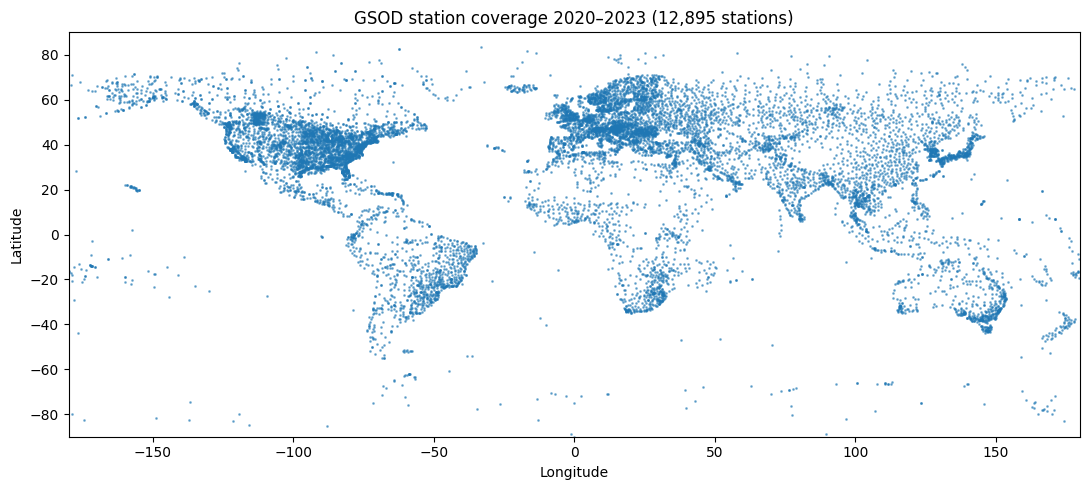

82.8% of stations are in the Northern Hemisphere


In [12]:
import matplotlib.pyplot as plt
stations = pq.groupBy("STATION").agg(F.first("LATITUDE").alias("lat"), F.first("LONGITUDE").alias("lon"),
                                     F.count("*").alias("days")).toPandas()
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(stations.lon, stations.lat, s=1, alpha=0.5)
ax.set(title=f"GSOD station coverage 2020–2023 ({len(stations):,} stations)", xlabel="Longitude", ylabel="Latitude",
       xlim=(-180, 180), ylim=(-90, 90))
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task1_station_map.png", dpi=150); plt.show()
north = (stations.lat >= 0).mean()
print(f"{north:.1%} of stations are in the Northern Hemisphere")